**TUGAS TEXT PREPROCESSING PEMROSESAN TEKS**

Eifellyne Putri Widayanto (011)

Vania Felicia Gita Wulandari (058)

Preprocessing teks hasil scraping sebelumnya (Billboard Hot 100 dan iTunes API)

HTTP Web Scraping (HTML)

In [193]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
url = 'https://www.billboard.com/charts/hot-100/'
headers = {
  'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
}

In [194]:
response = requests.get(url, headers=headers)
response.status_code

200

In [195]:
ds = BeautifulSoup(response.text, 'html.parser')
type(ds)

bs4.BeautifulSoup

In [196]:
print("Title Tag  :", ds.title)
print("Title Text :", ds.title.text.strip())
first_h3 = ds.h3
print("Elemen H3  :", first_h3)
print("Nama Tag   :", first_h3.name)
print("Isi Teks   :", first_h3.text.strip())

Title Tag  : <title>Billboard Hot 100™</title>
Title Text : Billboard Hot 100™
Elemen H3  : <h3 class="charts-nav-item-heading lrv-u-flex lrv-u-align-items-center lrv-u-color-white u-padding-r-13" id="charts-menu-item-2025-year-end">
<a class="c-link lrv-a-unstyle-link a-font-basic-fancy-xs u-letter-spacing-0028 u-font-size-14 u-font-size-18@mobile-max u-min-width-65p u-padding-l-13 u-padding-tb-10 u-padding-l-20@mobile-max lrv-u-color-white lrv-u-color-black:hover u-link-decoration-underline:hover" href="https://www.billboard.com/charts/year-end/">
	2025 Year End</a>
<button aria-label="charts-menu-expand" class="lrv-a-unstyle-button u-display-inline-flex lrv-u-margin-l-auto lrv-u-padding-l-050 u-padding-tb-10 lrv-a-icon-after a-icon-arrow-chart-nav-down" data-collapsible-toggle="always-show">
<span>
<span class="lrv-a-screen-reader-only">
					Expand 2025-year-end menu				</span>
</span>
</button>
</h3>
Nama Tag   : h3
Isi Teks   : 2025 Year End



					Expand 2025-year-end menu


In [197]:
chart_items = ds.find_all('ul', class_='o-chart-results-list-row')
sample = chart_items[0]
sample_title = sample.find('h3', id='title-of-a-story')
sample_artist = sample_title.find_next('span') if sample_title else None
print("Judul (Sampel)    :", sample_title.text.strip())
print("Penyanyi (Sampel) :", sample_artist.text.strip())

Judul (Sampel)    : Patient Zero
Penyanyi (Sampel) : Taylor Swift


In [198]:
songs = []
artists = []
for item in chart_items:
  title_elem = item.find('h3', id='title-of-a-story')
  artist_elem = title_elem.find_next('span') if title_elem else None
  if title_elem and artist_elem:
    songs.append(title_elem.text.strip())
    artists.append(artist_elem.text.strip())
len(songs), len(artists)

(100, 100)

In [199]:
df_billboard = pd.DataFrame({
  'Peringkat': range(1, len(songs) + 1),
  'Judul Lagu': songs,
  'Penyanyi': artists
})
df_billboard

,Peringkat,Judul Lagu,Penyanyi
0,1,Patient Zero,Taylor Swift
1,2,Choosin' Texas,Ella Langley
2,3,Cleveland!,Taylor Swift
3,4,Babylon,Taylor Swift
4,5,Pink Clouding,Taylor Swift
...,...,...,...
95,96,Kingdom Of Fear,Cameron Whitcomb
96,97,u + me = <3,Olivia Rodrigo
97,98,Washed,ELEVATION RHYTHM
98,99,Begged,Olivia Rodrigo


API Request (JSON)

In [200]:
import requests
import pandas as pd
query_artist = 'Taylor Swift'
max_result = 20
url_api = f"https://itunes.apple.com/search?term={query_artist}&limit={max_result}&entity=song"

In [201]:
response = requests.get(url_api)
response.status_code

200

In [202]:
ds = response.json()
type(ds)

dict

In [203]:
print("Keys utama:", ds.keys())
print("Total data:", ds.get('resultCount'))

Keys utama: dict_keys(['resultCount', 'results'])
Total data: 20


In [204]:
sample_data = ds['results'][0]
sample_title = sample_data.get('trackName')
sample_artist = sample_data.get('artistName')
sample_album = sample_data.get('collectionName')
sample_title, sample_artist, sample_album

('Patient Zero', 'Taylor Swift', 'The Life of a Showgirl: The Encore')

In [205]:
song_titles = []
artist_names = []
album_names = []
for item in ds.get('results', []):
  song_titles.append(item.get('trackName'))
  artist_names.append(item.get('artistName'))
  album_names.append(item.get('collectionName'))
len(song_titles), len(artist_names), len(album_names)

(20, 20, 20)

In [206]:
df_itunes = pd.DataFrame({
  'No': range(1, len(song_titles) + 1),
  'Judul Lagu': song_titles,
  'Penyanyi': artist_names,
  'Album': album_names
})
df_itunes

,No,Judul Lagu,Penyanyi,Album
0,1,Patient Zero,Taylor Swift,The Life of a Showgirl: The Encore
1,2,Cleveland!,Taylor Swift,The Life of a Showgirl: The Encore
2,3,Pink Clouding,Taylor Swift,The Life of a Showgirl: The Encore
3,4,Babylon,Taylor Swift,The Life of a Showgirl: The Encore
4,5,"I Knew It, I Knew You (From ""Toy Story 5"")",Taylor Swift,"I Knew It, I Knew You (From ""Toy Story 5"") - S..."
5,6,Shake It Off,Taylor Swift,1989
6,7,Wildest Dreams,Taylor Swift,1989 (Deluxe Edition)
7,8,You Belong With Me,Taylor Swift,Fearless (Platinum Edition)
8,9,Cruel Summer,Taylor Swift,Lover
9,10,Blank Space (Taylor's Version),Taylor Swift,1989 (Taylor's Version)


HTTP Web Scraping (HTML) - Billboard Hot 100

In [207]:
import warnings
warnings.filterwarnings(action='ignore')
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [208]:
url = 'https://www.billboard.com/charts/hot-100/'
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
response = requests.get(url, headers=headers)
ds = BeautifulSoup(response.text, 'html.parser')
chart_items = ds.find_all('ul', class_='o-chart-results-list-row')
songs, artists = [], []
for item in chart_items:
  title_elem = item.find('h3', id='title-of-a-story')
  artist_elem = title_elem.find_next('span') if title_elem else None
  if title_elem and artist_elem:
    songs.append(title_elem.text.strip())
    artists.append(artist_elem.text.strip())
df_billboard = pd.DataFrame({
  'Peringkat': range(1, len(songs) + 1),
  'Judul Lagu': songs,
  'Penyanyi': artists
})
df_billboard.head()

,Peringkat,Judul Lagu,Penyanyi
0,1,Patient Zero,Taylor Swift
1,2,Choosin' Texas,Ella Langley
2,3,Cleveland!,Taylor Swift
3,4,Babylon,Taylor Swift
4,5,Pink Clouding,Taylor Swift


API Request (JSON) - iTunes

In [209]:
query_artist = 'Taylor Swift'
max_result = 20
url_api = f"https://itunes.apple.com/search?term={query_artist}&limit={max_result}&entity=song"
response = requests.get(url_api)
ds = response.json()
song_titles, artist_names, album_names = [], [], []
for item in ds.get('results', []):
  song_titles.append(item.get('trackName'))
  artist_names.append(item.get('artistName'))
  album_names.append(item.get('collectionName'))
df_itunes = pd.DataFrame({
  'No': range(1, len(song_titles) + 1),
  'Judul Lagu': song_titles,
  'Penyanyi': artist_names,
  'Album': album_names
})
df_itunes.head()

,No,Judul Lagu,Penyanyi,Album
0,1,Patient Zero,Taylor Swift,The Life of a Showgirl: The Encore
1,2,Cleveland!,Taylor Swift,The Life of a Showgirl: The Encore
2,3,Pink Clouding,Taylor Swift,The Life of a Showgirl: The Encore
3,4,Babylon,Taylor Swift,The Life of a Showgirl: The Encore
4,5,"I Knew It, I Knew You (From ""Toy Story 5"")",Taylor Swift,"I Knew It, I Knew You (From ""Toy Story 5"") - S..."


In [210]:
df = pd.concat([
  df_billboard[['Judul Lagu', 'Penyanyi']].assign(Sumber='Billboard Hot 100'),
  df_itunes[['Judul Lagu', 'Penyanyi']].assign(Sumber='iTunes API'),
], ignore_index=True)
df.rename(columns={'Judul Lagu': 'text'}, inplace=True)
df.head()

,text,Penyanyi,Sumber
0,Patient Zero,Taylor Swift,Billboard Hot 100
1,Choosin' Texas,Ella Langley,Billboard Hot 100
2,Cleveland!,Taylor Swift,Billboard Hot 100
3,Babylon,Taylor Swift,Billboard Hot 100
4,Pink Clouding,Taylor Swift,Billboard Hot 100


In [211]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      120 non-null    object
 1   Penyanyi  120 non-null    object
 2   Sumber    120 non-null    object
dtypes: object(3)
memory usage: 2.9+ KB


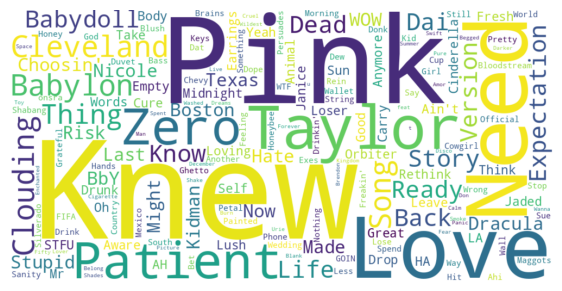

In [212]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
text = ' '.join(df['text'].dropna().astype(str))
wordcloud = WordCloud(width=1000, height=500, background_color='white', max_words=500).generate(text)
plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

remove HTML tags

In [213]:
import re
def remove_html(text):
  html_pattern = re.compile('<.*?>')
  return html_pattern.sub(r'', str(text))

remove hastag

In [214]:
def remove_hashtag(text):
  return re.sub(r'#\w+', '', text)

lower casing

In [215]:
def lower_casing(text):
  return str.lower(text)

remove URL, HTTP, and e-mail

In [216]:
def remove_rls(text):
  text = re.sub(r'https?\/\/S+', '',  str(text)) # remove the hyperlink
  text = re.sub(r'http\S+', '',  str(text)) # remove the hyperlink
  text = re.sub(r'www\S+', '',  str(text)) # remove the www
  text = re.sub(r'\S+@\S+', '', str(text)) # remove the email
  return text

remove punctuations

In [217]:
def remove_punctuation_list(text):
  # List Emoticon
  text = re.sub(r'(:\)|:-\)|:D|:-D|;\)|;-\))', '', text)
  text = re.sub(r'(:\(|:-\()', '', text)
  text = re.sub(r'(:v|:-v)', '', text)
  # remove punctuation
  text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~]', ' ', text)
  text = re.sub(r'\s+', ' ', text).strip()
  return text

removal of emojis

In [218]:
!pip install demoji

In [219]:
import demoji
def remove_emoji(text):
  cleaned_text = demoji.replace(text, repl="") # Replaces emojis with an empty string
  return cleaned_text

stemmer

In [220]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
def stem_kalimat(text):
  return " ".join([ps.stem(word) for word in str(text).split()])

remove stopword

In [221]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
sw = set(stopwords.words('english'))
def remove_stopwords(text):
  return " ".join([word for word in str(text).split() if word not in sw])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


applied in song titles (Billboard Hot 100 + iTunes)

In [222]:
df['rm_html'] = df['text'].apply(remove_html)
df[['text', 'rm_html']].head()

,text,rm_html
0,Patient Zero,Patient Zero
1,Choosin' Texas,Choosin' Texas
2,Cleveland!,Cleveland!
3,Babylon,Babylon
4,Pink Clouding,Pink Clouding


In [223]:
df['rm_hashtag'] = df['rm_html'].apply(remove_hashtag)
df[['rm_html', 'rm_hashtag']].head()

,rm_html,rm_hashtag
0,Patient Zero,Patient Zero
1,Choosin' Texas,Choosin' Texas
2,Cleveland!,Cleveland!
3,Babylon,Babylon
4,Pink Clouding,Pink Clouding


In [224]:
df['lower_case'] = df['rm_hashtag'].apply(lower_casing)
df[['rm_hashtag', 'lower_case']].head()

,rm_hashtag,lower_case
0,Patient Zero,patient zero
1,Choosin' Texas,choosin' texas
2,Cleveland!,cleveland!
3,Babylon,babylon
4,Pink Clouding,pink clouding


In [225]:
df['rm_url'] = df['lower_case'].apply(remove_rls)
df[['lower_case', 'rm_url']].head()

,lower_case,rm_url
0,patient zero,patient zero
1,choosin' texas,choosin' texas
2,cleveland!,cleveland!
3,babylon,babylon
4,pink clouding,pink clouding


In [226]:
df['rm_punc'] = df['rm_url'].apply(remove_punctuation_list)
df[['rm_url', 'rm_punc']].head()

,rm_url,rm_punc
0,patient zero,patient zero
1,choosin' texas,choosin texas
2,cleveland!,cleveland
3,babylon,babylon
4,pink clouding,pink clouding


In [227]:
df['rm_emoji'] = df['rm_punc'].apply(remove_emoji)
df[['rm_punc', 'rm_emoji']].head()

,rm_punc,rm_emoji
0,patient zero,patient zero
1,choosin texas,choosin texas
2,cleveland,cleveland
3,babylon,babylon
4,pink clouding,pink clouding


In [228]:
df['stem'] = df['rm_emoji'].apply(lambda x: stem_kalimat(x) if isinstance(x, str) else '')
df[['rm_emoji', 'stem']].head()

,rm_emoji,stem
0,patient zero,patient zero
1,choosin texas,choosin texa
2,cleveland,cleveland
3,babylon,babylon
4,pink clouding,pink cloud


In [229]:
df['rm_stopwords'] = df['stem'].apply(remove_stopwords)
df[['stem', 'rm_stopwords']].head()

,stem,rm_stopwords
0,patient zero,patient zero
1,choosin texa,choosin texa
2,cleveland,cleveland
3,babylon,babylon
4,pink cloud,pink cloud


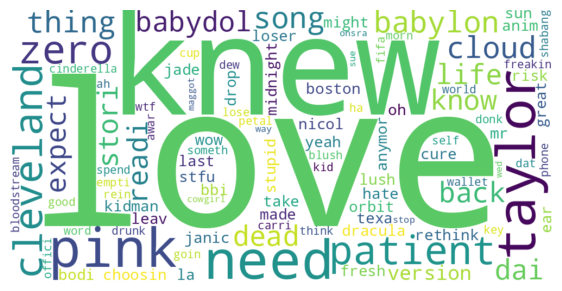

In [230]:
text = ' '.join(df['rm_stopwords'].dropna().astype(str))
wordcloud = WordCloud(width=1000, height=500, background_color='white', max_words=100).generate(text)
plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [231]:
df.rename(columns={'rm_stopwords': 'prepro'}, inplace=True)
df[['Sumber', 'text', 'prepro']]

,Sumber,text,prepro
0,Billboard Hot 100,Patient Zero,patient zero
1,Billboard Hot 100,Choosin' Texas,choosin texa
2,Billboard Hot 100,Cleveland!,cleveland
3,Billboard Hot 100,Babylon,babylon
4,Billboard Hot 100,Pink Clouding,pink cloud
...,...,...,...
115,iTunes API,Lover,lover
116,iTunes API,Enchanted (Taylor's Version),enchant taylor version
117,iTunes API,ME! (feat. Brendon Urie of Panic! At The Disco),feat brendon uri panic disco
118,iTunes API,You Need To Calm Down,need calm


In [232]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        120 non-null    object
 1   Penyanyi    120 non-null    object
 2   Sumber      120 non-null    object
 3   rm_html     120 non-null    object
 4   rm_hashtag  120 non-null    object
 5   lower_case  120 non-null    object
 6   rm_url      120 non-null    object
 7   rm_punc     120 non-null    object
 8   rm_emoji    120 non-null    object
 9   stem        120 non-null    object
 10  prepro      120 non-null    object
dtypes: object(11)
memory usage: 10.4+ KB


In [233]:
import warnings
warnings.filterwarnings(action='ignore')
import pandas as pd
import requests
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [234]:
df_prepro = df[['Sumber', 'Penyanyi', 'text', 'prepro']].copy()
df_prepro = df_prepro[df_prepro['Sumber'] == 'iTunes API'].reset_index(drop=True)   # feature engineering: iTunes saja
df_prepro['prepro'] = df_prepro['prepro'].fillna('').str.strip()
print('Jumlah baris iTunes    :', len(df_prepro))
print('Baris prepro kosong   :', (df_prepro['prepro'] == '').sum())

df_prepro = df_prepro[df_prepro['prepro'] != ''].reset_index(drop=True)
print('Jumlah baris sesudah  :', len(df_prepro))
df_prepro.to_csv('itunes_preprocessed.csv', index=False)

df_pre = df_prepro['prepro']
df_pre.head(10)

Jumlah baris iTunes    : 20
Baris prepro kosong   : 0
Jumlah baris sesudah  : 20


,prepro
0,patient zero
1,cleveland
2,pink cloud
3,babylon
4,knew knew toy stori 5
5,shake
6,wildest dream
7,belong
8,cruel summer
9,blank space taylor version


Feature Engineering Part 1

1. One Hot Encoding

In [235]:
vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(df_pre)
X_ohe = X
df_ohe = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
print('Ukuran matriks (dokumen x kosakata):', df_ohe.shape)
df_ohe

Ukuran matriks (dokumen x kosakata): (20, 42)


,babylon,back,belong,blank,brendon,burn,calm,cleveland,cloud,cruel,...,stori,summer,swift,taylor,toy,uri,version,wanna,wildest,zero
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
7,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
9,0,0,0,1,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0


Bag of Words (frekuensi kata)

In [236]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df_pre)
X_bow = X
df_bow = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
print('Ukuran matriks (dokumen x kosakata):', df_bow.shape)
df_bow

Ukuran matriks (dokumen x kosakata): (20, 42)


,babylon,back,belong,blank,brendon,burn,calm,cleveland,cloud,cruel,...,stori,summer,swift,taylor,toy,uri,version,wanna,wildest,zero
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
7,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
9,0,0,0,1,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0


TF-IDF

In [237]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
X_tfidf = X
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
df_tfidf = df_FE
print('Ukuran matriks (dokumen x kosakata):', df_FE.shape)
df_FE

Ukuran matriks (dokumen x kosakata): (20, 42)


,babylon,back,belong,blank,brendon,burn,calm,cleveland,cloud,cruel,...,stori,summer,swift,taylor,toy,uri,version,wanna,wildest,zero
0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.707107
1,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.707107,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.408248,0.000000,0.00000,0.000000,0.408248,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.707107,0.000000
7,0.0,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.707107,...,0.000000,0.707107,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,0.0,0.000000,0.0,0.542183,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.430046,0.000000,0.000000,0.476587,0.000000,0.000000,0.000000


Analisis Part 1

In [238]:
top_bow = df_bow.sum().sort_values(ascending=False).head(10)
top_tfidf = df_tfidf.mean().sort_values(ascending=False).head(10)
display(pd.DataFrame({'kata (BoW)': top_bow.index, 'frekuensi': top_bow.values,
                      'kata (TF-IDF)': top_tfidf.index, 'rata-rata bobot': top_tfidf.values.round(4)}))

sparsity = 1 - (X_bow.count_nonzero() / (X_bow.shape[0] * X_bow.shape[1]))
print(f'Sparsity matriks BoW: {sparsity:.2%}')
print('Kata yang hanya muncul 1x:', int((df_bow.sum() == 1).sum()), 'dari', df_bow.shape[1], 'kata')

,kata (BoW),frekuensi,kata (TF-IDF),rata-rata bobot
0,taylor,3,taylor,0.0782
1,knew,2,version,0.0522
2,version,2,cleveland,0.0500
3,belong,1,man,0.0500
4,brendon,1,readi,0.0500
5,burn,1,shake,0.0500
6,calm,1,lover,0.0500
7,blank,1,belong,0.0500
8,babylon,1,babylon,0.0500
9,back,1,knew,0.0408


Sparsity matriks BoW: 94.64%
Kata yang hanya muncul 1x: 39 dari 42 kata


Analisis:

Kosakata ada 42 kata. Sparsity 94,64%. 39 dari 42 kata hanya muncul 1x.

Kata terbanyak: taylor (3), knew (2), version (2). Pembeda One Hot dan BoW terlihat pada knew, karena muncul 2x di satu judul.

TF-IDF teratas: taylor (0.0782), version (0.0522), lalu banyak kata dengan bobot sama 0.05 (cleveland, man, readi, dll.). knew turun ke urutan 10.

One Hot hanya mencatat ada/tidaknya kata (0/1), sedangkan BoW mencatat jumlah kemunculannya. Pada judul lagu yang pendek hampir semua kata muncul sekali per judul, sehingga isi kedua matriks hampir sama. Perbedaan baru terlihat pada judul yang mengulang kata.

TF-IDF memberi bobot lebih besar pada kata yang jarang muncul di korpus dan menurunkan bobot kata yang umum. Karena itu kata-kata yang paling sering muncul di BoW tidak selalu punya bobot tertinggi di TF-IDF.

Matriks sangat sparse (hampir semua nilainya 0) karena kosakata besar dan tiap judul hanya berisi 1-4 kata. Sebagian besar kata hanya muncul sekali.

Pada data ini fitur Part 1 kurang informatif untuk melihat kemiripan antar judul, karena hanya sedikit kata yang dipakai bersama.

Feature Engineering Part 2

Tokenize Sentence

In [239]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [240]:
from nltk import word_tokenize
from tqdm import tqdm

sentences = [word_tokenize(text.lower()) for text in tqdm(df_pre)]
sentences[:5]

100%|██████████| 20/20 [00:00<00:00, 20360.70it/s]


[['patient', 'zero'],
 ['cleveland'],
 ['pink', 'cloud'],
 ['babylon'],
 ['knew', 'knew', 'toy', 'stori', '5']]

Build Word2Vec Model

In [241]:
!pip install gensim
import gensim.models

model = gensim.models.Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0)

param

min_count=1: Includes words that appear at least once.

vector_size=100: Generates word vectors of 100 dimensions.


window=5: Considers a context window of 5 words before and after the target word.


sg=0: Uses CBOW model (default setting).


sg=1: Enables the Skip-Gram model (predicts context words given a target word).

In [242]:
model.save('judul_lagu.w2v')

In [243]:
model = gensim.models.Word2Vec.load('judul_lagu.w2v')

In [244]:
w2v = model.wv
print('Jumlah kata di kosakata:', len(w2v.index_to_key))
print('Ukuran vektor          :', w2v.vector_size)
w2v.index_to_key[:10]

Jumlah kata di kosakata: 46
Ukuran vektor          : 100


['taylor',
 'version',
 'knew',
 'burn',
 'pictur',
 'calm',
 'need',
 'disco',
 'panic',
 'uri']

In [245]:
w2v.vectors.shape, w2v.vector_size

((46, 100), 100)

In [246]:
kata_uji = w2v.index_to_key[0]
print('Kata paling sering:', kata_uji)
w2v.similar_by_key(kata_uji)

Kata paling sering: taylor


[('shade', 0.21885325014591217),
 ('uri', 0.21621443331241608),
 ('readi', 0.19543619453907013),
 ('cleveland', 0.1691875159740448),
 ('blank', 0.15162980556488037),
 ('dream', 0.14180095493793488),
 ('cruel', 0.10849478095769882),
 ('man', 0.09937167167663574),
 ('wildest', 0.09622299671173096),
 ('enchant', 0.0931011214852333)]

In [247]:
import numpy as np
import pandas as pd

In [248]:
def get_document_vector(tokens, model):
  valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
  if not valid_vectors:
    return np.zeros(model.vector_size)
  return np.mean(valid_vectors, axis=0)

X_features = np.array([get_document_vector(doc, model) for doc in sentences])
X_w2v = X_features
print('Ukuran fitur Word2Vec:', X_features.shape)
pd.DataFrame(X_features)

Ukuran fitur Word2Vec: (20, 100)


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.000108,0.004038,0.000302,0.000799,0.002617,-0.000993,0.001130,0.002593,0.003690,-0.002754,...,0.003024,0.002135,-0.000483,0.001413,-0.000411,-0.001796,-0.001967,0.005527,-0.007652,-0.007237
1,-0.002608,-0.007919,-0.008260,-0.007586,0.003554,-0.007588,-0.003711,0.006629,0.007400,-0.006398,...,0.004729,0.006386,-0.007450,0.008860,0.008283,0.009379,-0.009018,-0.003447,-0.000342,0.004167
2,-0.000700,0.002253,-0.005388,-0.008673,0.007125,-0.004098,0.001960,-0.001127,0.006264,0.001223,...,-0.000090,-0.001831,0.000530,-0.001115,-0.005190,-0.003638,-0.002436,-0.006332,0.000310,-0.006882
3,-0.004794,-0.004317,-0.004801,-0.009804,-0.000777,-0.007792,-0.004812,-0.007375,0.009936,-0.001356,...,0.009199,0.001805,0.009710,-0.009907,-0.001501,0.006900,-0.001463,-0.001757,-0.007079,-0.005666
4,-0.001416,-0.000347,-0.004085,-0.002056,0.001205,0.004539,-0.001719,-0.001443,-0.004503,0.002263,...,-0.003104,0.000413,0.001138,-0.002231,0.003009,0.003642,0.001164,0.000384,0.000482,-0.002279
5,0.005383,0.009811,-0.007055,-0.000583,-0.005065,0.006435,0.009657,-0.000333,0.005140,0.006539,...,-0.009064,0.003419,0.005346,0.003468,0.007793,0.001656,0.006270,0.008835,-0.000943,-0.000803
6,0.003216,-0.005244,0.000698,-0.002422,-0.007314,-0.003872,-0.004802,0.002520,0.002803,-0.004424,...,-0.000103,0.000203,0.005022,-0.001636,-0.004198,0.004099,-0.003484,0.002445,-0.003257,-0.002089
7,0.004801,-0.003628,-0.004265,0.001220,-0.004127,-0.005627,0.003143,0.008338,-0.006546,-0.009114,...,-0.005487,-0.009499,0.006968,-0.005536,-0.009321,0.002597,-0.004978,-0.007360,0.009731,-0.001586
8,0.002111,-0.009330,0.000977,0.000142,0.000267,-0.003270,-0.006858,-0.001661,0.008865,-0.004958,...,0.000944,0.001008,-0.002253,-0.004855,0.001234,-0.002909,0.001149,0.002099,0.003289,-0.007495
9,-0.003312,-0.000819,0.002372,0.004659,0.000711,-0.002505,0.002149,0.003478,-0.003380,-0.000922,...,0.000668,0.002315,0.003373,0.000551,0.005014,0.004217,-0.001413,-0.004616,-0.005691,0.001701


visualize

In [249]:
!pip install umap-learn plotly
from umap import UMAP
import plotly.express as px

In [250]:
X = UMAP(n_neighbors=min(15, len(w2v.index_to_key) - 1), random_state=42).fit_transform(w2v.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = w2v.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='Word2Vec Visualization')
fig.show()

Build FastText Model

In [251]:
model_fasttext = gensim.models.FastText(sentences, min_count=1,
                                        vector_size=100, window=5,
                                        min_n=3, max_n=6,
                                        sg=1, epochs=10)

param

vector_size=100 sets embedding size.

window=5 defines context window size.

min_n=3 and max_n=6 create character n-grams.

sg=1 enables Skip-Gram training.

epochs=10 controls training iterations.

In [252]:
model_fasttext.save('judul_lagu.fasttext')

In [253]:
model_fasttext = gensim.models.FastText.load('judul_lagu.fasttext')

In [254]:
fasttext = model_fasttext.wv
print('Jumlah kata di kosakata:', len(fasttext.index_to_key))
fasttext.index_to_key[:10]

Jumlah kata di kosakata: 46


['taylor',
 'version',
 'knew',
 'burn',
 'pictur',
 'calm',
 'need',
 'disco',
 'panic',
 'uri']

In [255]:
fasttext.vectors.shape

(46, 100)

In [256]:
print('Kata uji:', kata_uji)
fasttext.similar_by_key(kata_uji)

Kata uji: taylor


[('space', 0.21212497353553772),
 ('pink', 0.20854215323925018),
 ('uri', 0.17657959461212158),
 ('shade', 0.17264145612716675),
 ('version', 0.13511306047439575),
 ('shake', 0.12368723005056381),
 ('wildest', 0.12204790115356445),
 ('don', 0.11375272274017334),
 ('disco', 0.09679348021745682),
 ('cloud', 0.08870671689510345)]

In [257]:
X_features = np.array([get_document_vector(doc, model_fasttext) for doc in sentences])
X_ft = X_features
print('Ukuran fitur FastText:', X_features.shape)
pd.DataFrame(X_features)

Ukuran fitur FastText: (20, 100)


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.000534,-0.000749,0.000486,0.000180,-0.000564,0.000401,0.000833,0.000811,0.001274,0.001204,...,-0.000090,0.000800,-0.001632,0.001333,-0.000757,-0.000090,-0.001384,0.001864,0.000297,0.000194
1,-0.002566,-0.000877,0.000353,-0.001050,0.000277,0.000606,-0.001304,-0.001474,0.001093,-0.000858,...,0.000918,0.000854,-0.001840,0.001053,0.000626,-0.000253,-0.001434,0.000277,-0.000446,0.001493
2,0.001388,0.000203,-0.001516,-0.000133,0.000047,-0.000877,0.001828,0.000271,0.002123,-0.001447,...,-0.001296,-0.001116,0.000390,-0.000228,-0.001693,0.001021,-0.000493,-0.000731,0.001225,0.000030
3,-0.000815,0.003050,-0.002873,-0.001245,0.001869,0.002288,0.000501,-0.001090,-0.000041,0.000112,...,0.000522,-0.000563,0.002474,-0.001954,0.000229,-0.000160,-0.000096,0.000119,-0.000867,-0.001770
4,0.000144,0.001147,0.000604,-0.000976,-0.000820,-0.000460,-0.000161,-0.000889,-0.000388,-0.000289,...,-0.002566,-0.001034,-0.000361,-0.000055,0.002171,0.000314,0.000638,0.002100,-0.000778,0.000044
5,0.002686,0.003359,-0.001008,0.000140,-0.000385,0.000159,-0.000341,0.001394,0.001308,-0.000715,...,-0.002857,0.000023,0.000802,-0.002628,0.000165,0.002111,0.001030,0.000097,-0.000322,0.000647
6,0.001275,0.000944,-0.000823,-0.001269,-0.000067,-0.000121,-0.000359,0.001592,0.000293,0.000639,...,0.001245,0.000024,0.001563,0.000841,-0.001115,0.000221,0.000765,0.000898,-0.000721,-0.000585
7,-0.001742,-0.000429,0.001389,-0.000541,0.000938,0.000878,-0.002371,-0.000576,-0.000214,0.000192,...,-0.000369,0.000386,0.001557,-0.001791,0.001114,0.001771,-0.002578,0.000544,0.002488,-0.000302
8,-0.000472,-0.001858,-0.000097,-0.000805,-0.000479,0.000820,-0.000194,-0.001090,-0.000215,0.000322,...,-0.001780,-0.000586,-0.000140,0.000058,0.001130,-0.000389,-0.000274,0.000158,-0.001437,-0.001092
9,-0.000033,0.000080,-0.000405,-0.000477,-0.000274,0.000144,0.001014,-0.000738,0.000452,-0.000415,...,-0.000491,0.000729,0.000486,0.000380,-0.000936,-0.000192,-0.000182,-0.000931,0.000559,0.000450


In [258]:
X = UMAP(n_neighbors=min(15, len(fasttext.index_to_key) - 1), random_state=42).fit_transform(fasttext.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = fasttext.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='FastText Visualization')
fig.show()

Analisis Part 2

In [259]:
ringkasan = pd.DataFrame({
  'Metode': ['One Hot', 'Bag of Words', 'TF-IDF', 'Word2Vec (CBOW)', 'FastText (Skip-Gram)'],
  'Jenis fitur': ['sparse, 0/1', 'sparse, frekuensi', 'sparse, bobot', 'dense, rata-rata vektor kata', 'dense, rata-rata vektor kata'],
  'Dimensi': [X_ohe.shape[1], X_bow.shape[1], X_tfidf.shape[1], X_w2v.shape[1], X_ft.shape[1]],
})
display(ringkasan)

print('Word2Vec :', [w for w, s in w2v.similar_by_key(kata_uji, topn=5)])
print('FastText :', [w for w, s in fasttext.similar_by_key(kata_uji, topn=5)])
print('Skor similarity tertinggi -> Word2Vec: %.3f | FastText: %.3f' % (
  w2v.similar_by_key(kata_uji, topn=1)[0][1], fasttext.similar_by_key(kata_uji, topn=1)[0][1]))

,Metode,Jenis fitur,Dimensi
0,One Hot,"sparse, 0/1",42
1,Bag of Words,"sparse, frekuensi",42
2,TF-IDF,"sparse, bobot",42
3,Word2Vec (CBOW),"dense, rata-rata vektor kata",100
4,FastText (Skip-Gram),"dense, rata-rata vektor kata",100


Word2Vec : ['shade', 'uri', 'readi', 'cleveland', 'blank']
FastText : ['space', 'pink', 'uri', 'shade', 'version']
Skor similarity tertinggi -> Word2Vec: 0.219 | FastText: 0.212


Kesimpulan

Dimensi dan bentuk fitur. Part 1 (One Hot, BoW, TF-IDF) berdimensi 42 dan sparse (94,64% berisi 0). Word2Vec dan FastText berdimensi 100 dan dense.

Hasil Word2Vec.
1. Kosakata 46 kata.
2. Kata mirip taylor: shade, uri, readi, dengan skor tertinggi 0.219.
3. Skornya rendah dan kata-katanya tidak berhubungan makna.

Hasil FastText.
1. Kata mirip taylor: space, pink, uri, dengan skor tertinggi 0.212.
2. Sama rendahnya dengan Word2Vec dan sama-sama tidak bermakna.
3. Kedua model sama-sama memunculkan uri dan shade, jadi hasilnya terlihat acak.

Penyebabnya. Datanya terlalu kecil (sekitar 20 judul, tiap judul 1–4 kata), sehingga model tidak punya cukup konteks untuk belajar hubungan antar kata.

Kata dominan. taylor dan version paling sering muncul karena judul seperti “(Taylor’s Version)”, bukan karena maknanya.

Visualisasi UMAP. Lihat grafik di notebook kalian. Kalau titik-titiknya tersebar tanpa kelompok jelas, tulis begitu. Aku belum melihat tampilan grafiknya, jadi sesuaikan dengan yang tampil di layar.

Kesimpulan. Untuk data sekecil ini, TF-IDF paling mudah ditafsirkan (kata penciri tiap judul terlihat). Word2Vec dan FastText baru berguna kalau datanya jauh lebih banyak (misalnya lebih banyak lagu atau pakai lirik).